# RNA para clasificación de imágenes: perros vs gatos

Clasificador binario (perro / gato) sobre el dataset de Asirra (Petfinder + Microsoft) usando la backbone convolucional de **EfficientNet-B0** entrenada desde cero (`weights=None`).

**Restricciones del entorno** (Codespace con ~8 GB de RAM, 2 CPUs y sin GPU):
- Al tener menos de 12 GB de RAM, las imágenes se cargan progresivamente con `ImageDataGenerator` + `flow_from_directory()`.
- Entrenar EfficientNet-B0 desde cero en CPU es lento (unas pocas imágenes por segundo), por lo que con las 25.000 fotos cada época tardaría más de 40 min. Por eso se trabaja con una **muestra configurable** (`SAMPLE_PER_CLASS`); poniéndolo a `None` se usa el dataset completo.
- Imágenes de 200x200 y `BATCH_SIZE = 4`: con 224x224 o lotes más grandes el entrenamiento supera la memoria disponible y el kernel muere.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import gc
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import keras
from keras.applications import EfficientNetB0
from keras.models import Sequential, load_model
from keras.layers import Dense, GlobalAveragePooling2D
from keras.callbacks import ModelCheckpoint, EarlyStopping
# En Keras 3 ImageDataGenerator ya no está en keras.preprocessing, sigue disponible vía tensorflow.keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
# Configuración
SEED = 42
IMG_SIZE = (200, 200)      # tamaño fijo pedido en el enunciado
BATCH_SIZE = 16
SAMPLE_PER_CLASS = 2000    # imágenes por clase a usar; None = las 12.500 de cada clase
BASE_EPOCHS = 5            # épocas del modelo base (paso 3)
EPOCHS = 15                # época máxima total; el paso 4 continúa desde BASE_EPOCHS

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw" / "train"
PROCESSED_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"

keras.utils.set_random_seed(SEED)

## Paso 1: Carga del conjunto de datos

Las fotos están en `data/raw/train` y la etiqueta viene en el nombre del archivo (`cat.123.jpg`, `dog.456.jpg`).

In [3]:
files = sorted(f for f in os.listdir(RAW_DIR) if f.endswith(".jpg"))
df = pd.DataFrame({"filename": files, "label": [f.split(".")[0] for f in files]})

print(f"Total de imágenes: {len(df)}")
df["label"].value_counts()

Total de imágenes: 25000


label
cat    12500
dog    12500
Name: count, dtype: int64

`flow_from_directory()` necesita una carpeta por split y, dentro, una subcarpeta por clase. Se divide la muestra de forma estratificada en:
- **train (70%)**: entrenamiento.
- **validation (15%)**: seguimiento por época y selección del mejor modelo (callbacks).
- **test (15%)**: evaluación final; el modelo no lo ve hasta el final.

In [4]:
if SAMPLE_PER_CLASS is not None:
    df = df.groupby("label").sample(n=SAMPLE_PER_CLASS, random_state=SEED).reset_index(drop=True)

train_df, rest_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(rest_df, test_size=0.50, stratify=rest_df["label"], random_state=SEED)

splits = {"train": train_df, "validation": val_df, "test": test_df}

# Se regenera la estructura desde cero para que el notebook sea re-ejecutable
for split, split_df in splits.items():
    shutil.rmtree(PROCESSED_DIR / split, ignore_errors=True)
    for label in ["cat", "dog"]:
        (PROCESSED_DIR / split / label).mkdir(parents=True)
    for filename, label in zip(split_df["filename"], split_df["label"]):
        shutil.copy(RAW_DIR / filename, PROCESSED_DIR / split / label / filename)

pd.DataFrame({split: split_df["label"].value_counts() for split, split_df in splits.items()})

,train,validation,test
label,,,
cat,1400,300,300
dog,1400,300,300


## Paso 2: Visualiza la información de entrada

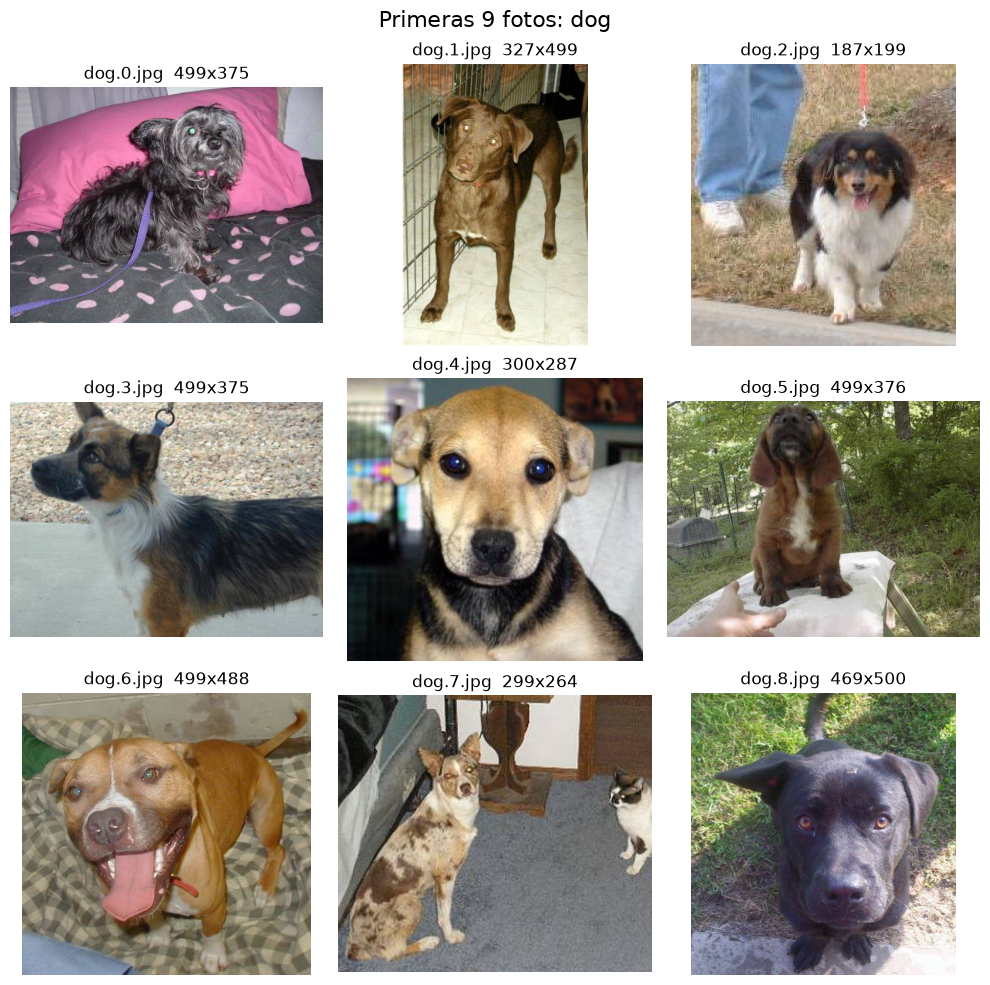

In [5]:
def plot_first_nine(label):
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    for ax, i in zip(axes.flat, range(9)):
        img = Image.open(RAW_DIR / f"{label}.{i}.jpg")
        ax.imshow(img)
        ax.set_title(f"{label}.{i}.jpg  {img.size[0]}x{img.size[1]}")
        ax.axis("off")
    fig.suptitle(f"Primeras 9 fotos: {label}", fontsize=16)
    plt.tight_layout()
    plt.show()


plot_first_nine("dog")

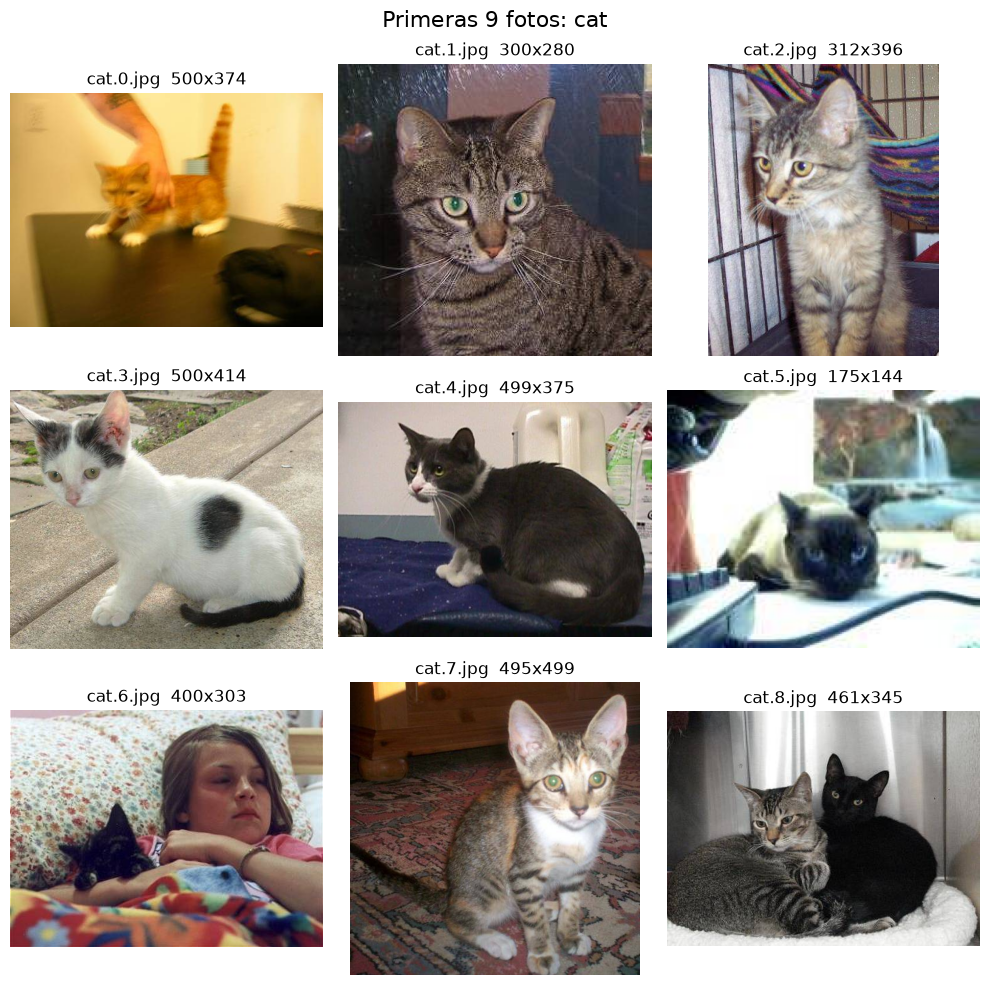

In [6]:
plot_first_nine("cat")

Las fotos son a color y cada una tiene un tamaño distinto. Veamos la distribución de tamaños en la muestra:

        ancho    alto
count  4000.0  4000.0
mean    404.0   360.0
std     108.4    96.9
min      54.0    55.0
25%     324.0   300.0
50%     447.0   374.0
75%     499.0   419.0
max     500.0   500.0


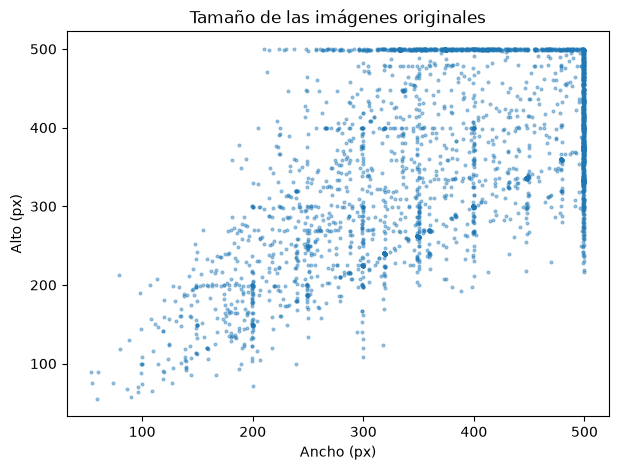

In [7]:
sizes = pd.DataFrame([Image.open(RAW_DIR / f).size for f in df["filename"]], columns=["ancho", "alto"])
print(sizes.describe().round(1))

plt.figure(figsize=(7, 5))
plt.scatter(sizes["ancho"], sizes["alto"], s=4, alpha=0.4)
plt.xlabel("Ancho (px)")
plt.ylabel("Alto (px)")
plt.title("Tamaño de las imágenes originales")
plt.show()

Hay que llevarlas todas a un tamaño fijo: se redimensionan a **200x200**, como pide el enunciado. La arquitectura propuesta usa `input_shape = (224, 224, 3)`, pero entrenar a 224x224 no cabe en la memoria de este entorno, así que la entrada de la red se adapta a `(200, 200, 3)`. EfficientNet-B0 acepta cualquier resolución de entrada porque `GlobalAveragePooling2D` reduce los mapas de características a un vector de tamaño fijo.

Se crean dos `ImageDataGenerator`:
- `trdata` para entrenamiento, con aumento de datos ligero (volteo horizontal, zoom, rotación) para que el modelo sea más robusto a animales descentrados o en distintas posiciones.
- `tsdata` sin transformaciones, para validación y test.

**No se usa `rescale=1./255`**: el `EfficientNetB0` de Keras incluye su propia capa de normalización y espera píxeles en el rango [0, 255].

`class_mode="categorical"` genera etiquetas one-hot, que es lo que espera la capa final `Dense(2, softmax)`. En validación y test `shuffle=False` para que las predicciones queden alineadas con las etiquetas reales.

In [8]:
trdata = ImageDataGenerator(horizontal_flip=True, zoom_range=0.1, rotation_range=15)
tsdata = ImageDataGenerator()

flow_args = dict(target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical")
train_gen = trdata.flow_from_directory(PROCESSED_DIR / "train", shuffle=True, seed=SEED, **flow_args)
val_gen = tsdata.flow_from_directory(PROCESSED_DIR / "validation", shuffle=False, **flow_args)
test_gen = tsdata.flow_from_directory(PROCESSED_DIR / "test", shuffle=False, **flow_args)

class_names = list(train_gen.class_indices)
train_gen.class_indices

Found 2800 images belonging to 2 classes.
Found 600 images belonging to 2 classes.
Found 600 images belonging to 2 classes.


{'cat': 0, 'dog': 1}

Forma del lote: (16, 200, 200, 3) | rango de píxeles: 0.0 - 255.0


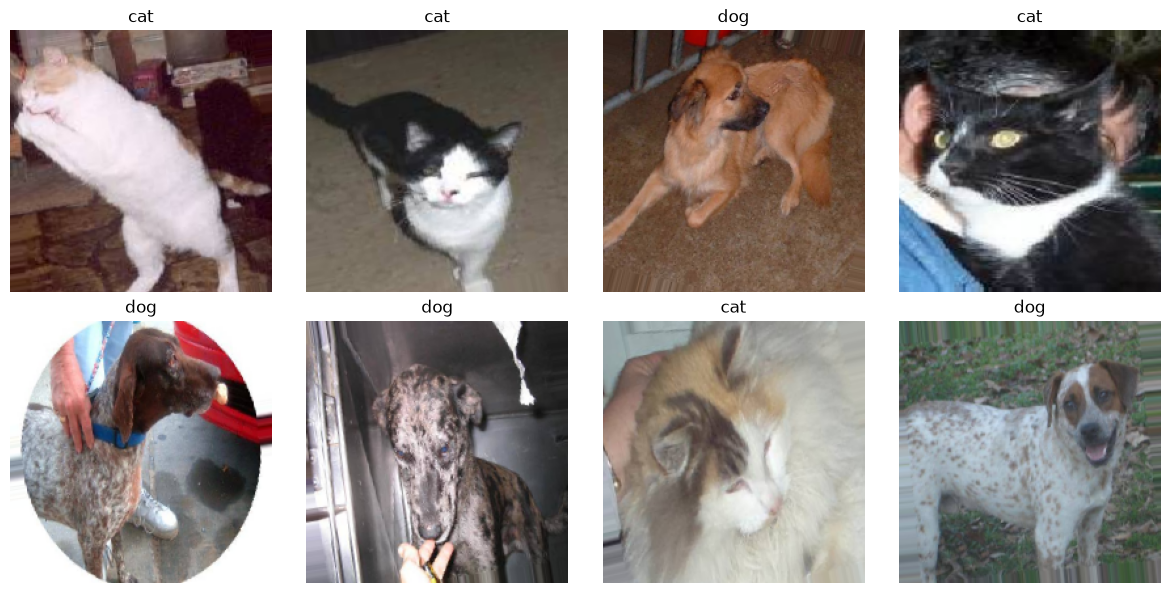

In [9]:
# Un lote tal y como entra a la red: 200x200 y con el aumento de datos aplicado
x_batch, y_batch = next(train_gen)
print("Forma del lote:", x_batch.shape, "| rango de píxeles:", x_batch.min(), "-", x_batch.max())

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, label in zip(axes.flat, x_batch, y_batch):
    ax.imshow(img.astype("uint8"))
    ax.set_title(class_names[label.argmax()])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Paso 3: Construye una RNA

Arquitectura de prueba del enunciado: backbone de EfficientNet-B0 sin la cabeza de clasificación, `GlobalAveragePooling2D` para reducir los mapas de características a un vector y dos capas `Dense` para la clasificación perro/gato.

Elementos restantes para completar el modelo:
- **Optimizador** `adam`.
- **Pérdida** `categorical_crossentropy` (salida softmax de 2 unidades con etiquetas one-hot).
- **Métrica** `accuracy`.
- `jit_compile=False`: la compilación XLA que Keras activa por defecto dispara el consumo de RAM en CPU.

In [10]:
def build_model():
    model = Sequential()
    model.add(EfficientNetB0(include_top = False, weights = None, input_shape = IMG_SIZE + (3,)))
    model.add(GlobalAveragePooling2D())
    model.add(Dense(units = 128, activation = "relu"))
    model.add(Dense(units = 2, activation = "softmax"))
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"], jit_compile=False)
    return model


model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 4,171,774 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [11]:
history_base = model.fit(train_gen, validation_data=val_gen, epochs=BASE_EPOCHS)

Epoch 1/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 92s 432ms/step - accuracy: 0.5450 - loss: 0.7762 - val_accuracy: 0.5000 - val_loss: 0.9130
Epoch 2/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 77s 440ms/step - accuracy: 0.5975 - loss: 0.6763 - val_accuracy: 0.5000 - val_loss: 0.6968
Epoch 3/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 78s 443ms/step - accuracy: 0.6118 - loss: 0.6432 - val_accuracy: 0.6450 - val_loss: 0.6904
Epoch 4/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 82s 470ms/step - accuracy: 0.6604 - loss: 0.6195 - val_accuracy: 0.6217 - val_loss: 0.9809
Epoch 5/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 88s 505ms/step - accuracy: 0.6579 - loss: 0.6223 - val_accuracy: 0.6317 - val_loss: 0.6682


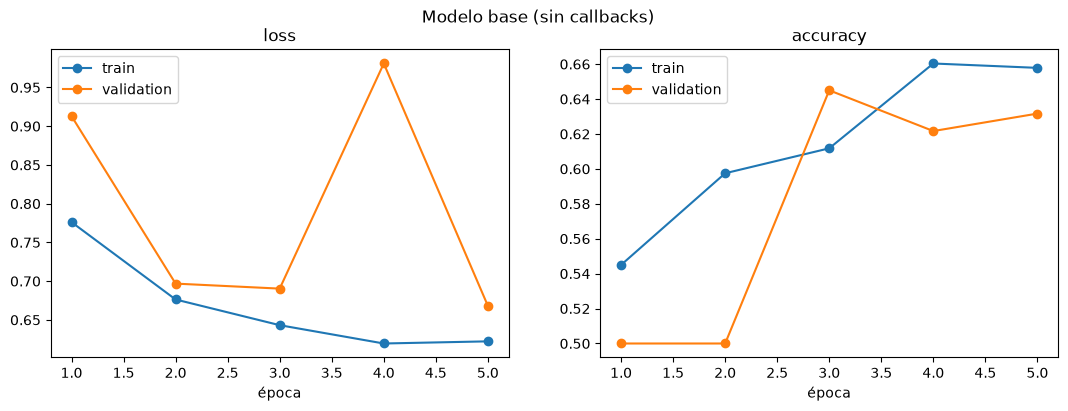

In [12]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    epochs = np.array(history.epoch) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, hist[metric], marker="o", label="train")
        ax.plot(epochs, hist[f"val_{metric}"], marker="o", label="validation")
        ax.set_title(metric)
        ax.set_xlabel("época")
        ax.legend()
    fig.suptitle(title)
    plt.show()


plot_history(history_base, "Modelo base (sin callbacks)")

In [13]:
base_test_loss, base_test_acc = model.evaluate(test_gen, verbose=0)
print(f"Modelo base -> test loss: {base_test_loss:.4f} | test accuracy: {base_test_acc:.4f}")

Modelo base -> test loss: 0.6679 | test accuracy: 0.6183


## Paso 4: Optimiza el modelo anterior

Se continúa entrenando el modelo anterior (desde la época `BASE_EPOCHS` hasta un máximo de `EPOCHS`) añadiendo dos callbacks:
- `ModelCheckpoint`: guarda en disco el modelo cada vez que mejora la `val_loss`, así nos quedamos con la mejor época y no con la última.
- `EarlyStopping`: detiene el entrenamiento si la `val_loss` no mejora en 4 épocas seguidas, evitando sobreajuste y tiempo de cómputo inútil.

Ambos vigilan la misma métrica (`val_loss`) para que coincidan en cuál es la mejor época.

Se reutiliza el mismo modelo en lugar de crear uno nuevo porque TensorFlow no devuelve al sistema la memoria de un modelo borrado, y con dos redes en memoria el kernel se queda sin RAM.

(`fit_generator` está obsoleto y en Keras 3 ya no existe: `fit` acepta generadores directamente.)

In [14]:
checkpoint_path = MODELS_DIR / "best_model.keras"
checkpoint = ModelCheckpoint(checkpoint_path, monitor="val_loss", mode="min", save_best_only=True, verbose=1)
early_stopping = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1)

history = model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS, initial_epoch=BASE_EPOCHS,
                    callbacks=[checkpoint, early_stopping])

Epoch 6/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 0.6875 - loss: 0.5972
Epoch 6: val_loss improved from None to 0.67156, saving model to /Users/miggy1312/Documents/machine learning/miguelangel-machine-learning-python/models/best_model.keras

Epoch 6: finished saving model to /Users/miggy1312/Documents/machine learning/miguelangel-machine-learning-python/models/best_model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 91s 521ms/step - accuracy: 0.6875 - loss: 0.5972 - val_accuracy: 0.6617 - val_loss: 0.6716
Epoch 7/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 519ms/step - accuracy: 0.7025 - loss: 0.5850
Epoch 7: val_loss improved from 0.67156 to 0.59235, saving model to /Users/miggy1312/Documents/machine learning/miguelangel-machine-learning-python/models/best_model.keras

Epoch 7: finished saving model to /Users/miggy1312/Documents/machine learning/miguelangel-machine-learning-python/models/best_model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 95s 545ms/step - accuracy: 0.7025 - loss: 0.5850 - val_a

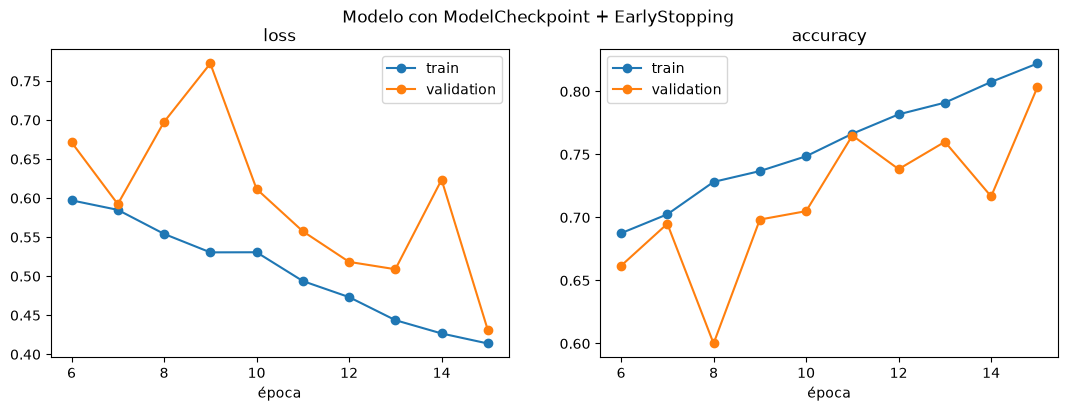

In [15]:
plot_history(history, "Modelo con ModelCheckpoint + EarlyStopping")

Se carga el mejor modelo guardado por `ModelCheckpoint` y se usa el conjunto de test para hacer predicciones. Antes se libera el modelo de entrenamiento para no tener dos redes en memoria.

In [16]:
del model
keras.backend.clear_session()
gc.collect()

best_model = load_model(checkpoint_path)

test_loss, test_acc = best_model.evaluate(test_gen, verbose=0)
print(f"Mejor modelo -> test loss: {test_loss:.4f} | test accuracy: {test_acc:.4f}")
print(f"Modelo base  -> test loss: {base_test_loss:.4f} | test accuracy: {base_test_acc:.4f}")

Mejor modelo -> test loss: 0.4032 | test accuracy: 0.8200
Modelo base  -> test loss: 0.6679 | test accuracy: 0.6183


38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step
              precision    recall  f1-score   support

         cat     0.7727    0.9067    0.8344       300
         dog     0.8871    0.7333    0.8029       300

    accuracy                         0.8200       600
   macro avg     0.8299    0.8200    0.8186       600
weighted avg     0.8299    0.8200    0.8186       600



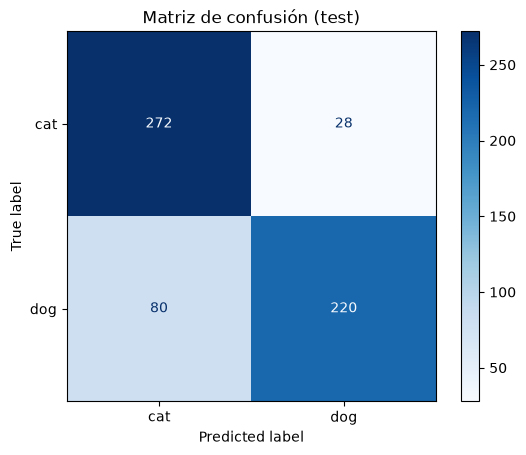

In [17]:
y_proba = best_model.predict(test_gen)
y_pred = y_proba.argmax(axis=1)
y_true = test_gen.classes

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(cmap="Blues")
plt.title("Matriz de confusión (test)")
plt.show()

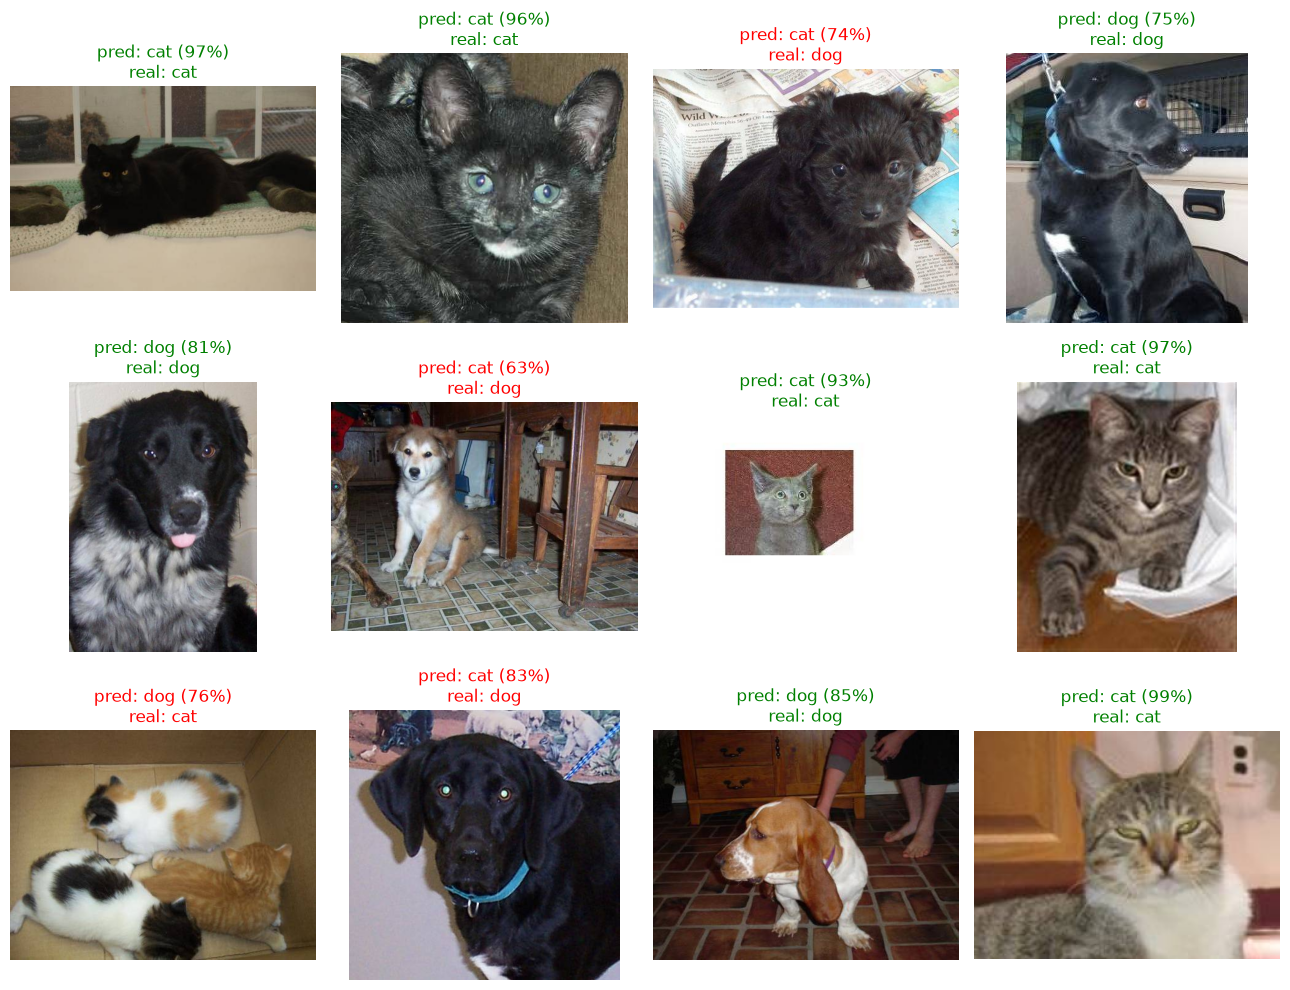

In [18]:
# Ejemplos de predicciones en test: título en verde si acierta, en rojo si falla
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, i in zip(axes.flat, rng.choice(len(y_true), size=min(12, len(y_true)), replace=False)):
    ax.imshow(Image.open(test_gen.filepaths[i]))
    ok = y_pred[i] == y_true[i]
    ax.set_title(f"pred: {class_names[y_pred[i]]} ({y_proba[i].max():.0%})\nreal: {class_names[y_true[i]]}",
                 color="green" if ok else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Paso 5: Guarda el modelo

In [19]:
final_model_path = MODELS_DIR / "cats_dogs_efficientnetb0.keras"
best_model.save(final_model_path)
print(f"Modelo guardado en {final_model_path} ({final_model_path.stat().st_size / 1e6:.1f} MB)")

Modelo guardado en /Users/miggy1312/Documents/machine learning/miguelangel-machine-learning-python/models/cats_dogs_efficientnetb0.keras (51.2 MB)


## Conclusiones

1. **Evolución del modelo base al modelo optimizado**:
   - **Modelo base (5 épocas)**: Obtuvo un `test_loss` de **0.6679** y un `test_accuracy` de **61.83%**. Al entrenarse **EfficientNet-B0** desde cero (`weights=None`), 5 épocas resultaron insuficientes para que los filtros convolucionales aprendieran representaciones discriminativas sólidas.
   - **Modelo optimizado (hasta 15 épocas con Callbacks)**: Continuar el entrenamiento con `ModelCheckpoint` y `EarlyStopping` permitió alcanzar el mejor desempeño en la **época 15** (`val_loss = 0.4309`, `val_accuracy = 80.33%`), logrando en el conjunto de **test** un `test_loss` de **0.4032** y un `test_accuracy` de **82.00%** (+20.17 puntos porcentuales de mejora respecto al modelo base).

2. **Desempeño por clase en el conjunto de prueba (600 imágenes)**:
   - **Gatos (`cat`)**: Precisión de **77.27%**, *recall* de **90.67%** y *F1-score* de **0.8344** (detecta la gran mayoría de los gatos reales).
   - **Perros (`dog`)**: Precisión de **88.71%**, *recall* de **73.33%** y *F1-score* de **0.8029** (cuando predice perro suele acertar, aunque confunde algunos perros con gatos).
   - **Balance global**: *F1-score macro* de **0.8186**, lo que demuestra un buen poder de generalización considerando que se entrenó desde cero con una muestra de 4.000 imágenes (2.000 por clase) y aumento de datos (*data augmentation*).

3. **Trabajo futuro y posibles mejoras**:
   - **Transfer Learning**: Inicializar `EfficientNetB0` con pesos preentrenados (`weights="imagenet"`) congelando las primeras capas permitiría superar el 95% de exactitud en menos épocas.
   - **Más datos y épocas**: Dado que la mejor `val_loss` se alcanzó justo en la época 15, el modelo aún tenía margen de mejora antes de sobreajustar, por lo que ampliar `SAMPLE_PER_CLASS` o el número de épocas con un *learning rate scheduler* (`ReduceLROnPlateau`) mejoraría aún más la métrica final.